In [1]:
import seaborn as sb
import numpy as np
import random
import math
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import functools as ft
import statistics
import scipy as sc

In [2]:
def get_pvalue_info_H1 (pvalue_generator, clr = "#00008B", label = "", level_array = [0.05, 0.01], mode_output = 0):
    table = [0]*len(level_array) # на i-ом месте стоит частота отвержения гипотезы на уровне alpha_i
    pvalue = pvalue_generator()
    N = len(pvalue)
    alpha = level_array

    if(N < 5):
        print("how am i supposed to test your criterion based on < 5 p-value values?", end = "\n")
        print("как я должен тестить ваш критерий, основываясь на < 5 значениях p-value?", end = "\n")
        print("anyway: ", end = "\n")

    for j in range ( len(alpha) ):
        freq = 0
        for p in pvalue:
            if p<alpha[j]:
                freq+=1/N
        table[j] = freq
        # заполнили табличку

    if(mode_output == 0): #на экран ничего, только возвращаем табличку
        return(table)

    if(mode_output == 1): # на экран только график ЭФР пи-вэлью
        l = np.linspace(0,1,100) # пока по умолчанию точность 1/100
        plt.legend()
        plt.title("график ЭФР пи-вэлью при вашей H1")
        plt.plot(l, sc.stats.ecdf(pvalue).cdf.evaluate(l), color = clr, label = label)
        plt.plot(l,l, color =  "#013220")
      
        return(table)

    if(mode_output == 2): #на экран только табличку
        for j in range ( len(level_array) ):
            print("частота отклонений H0 на уровне значимости ", alpha[j], ": ", table[j], end='\n')
        return(table)

    if(mode_output == 3): #на экран табличку и график ЭФР пи-вэлью
        l = np.linspace(0,1,100) # пока по умолчанию точность 1/100
        plt.title("график ЭФР пи-вэлью при вашей H1")
        plt.plot(l, sc.stats.ecdf(pvalue).cdf.evaluate(l), color = "#00008B")
        plt.plot(l,l, color = "#013220")
        plt.show()

        for j in range ( len(level_array) ):
             print("частота отклонений H0 на уровне значимости ", alpha[j], ": ", table[j], end='\n')
        return(table)

n =  10


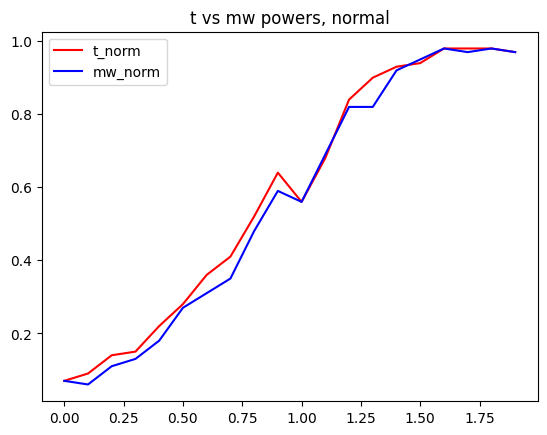

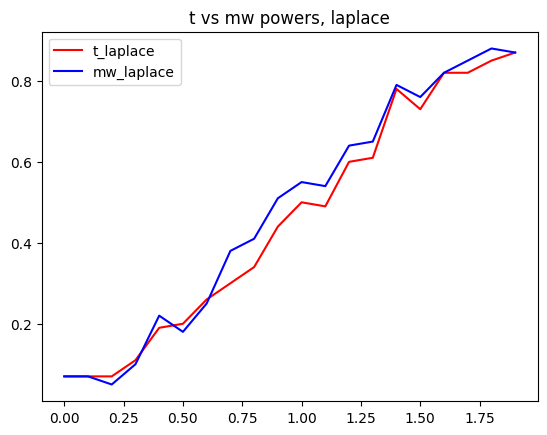

n =  50


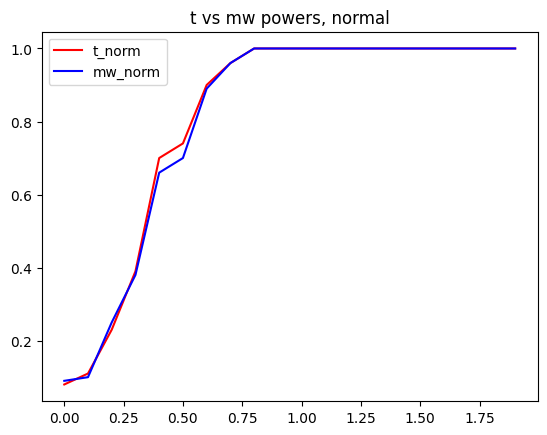

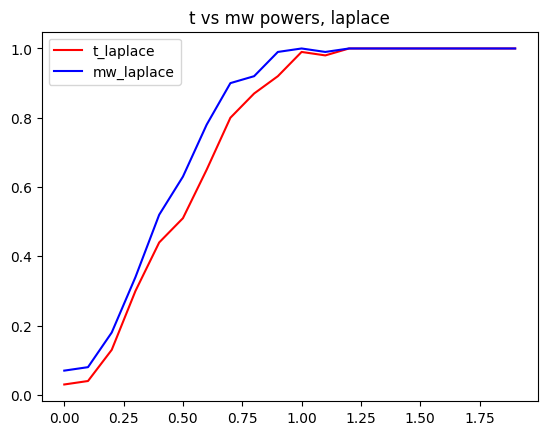

n =  100


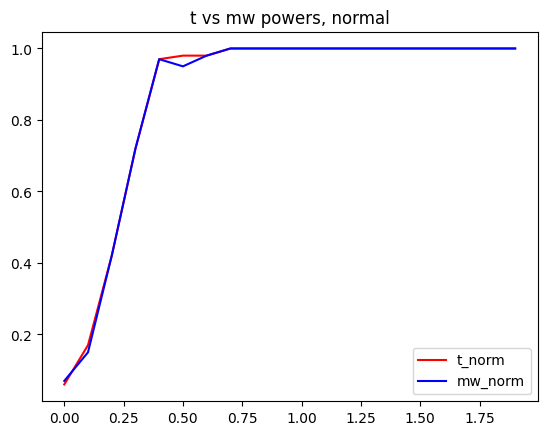

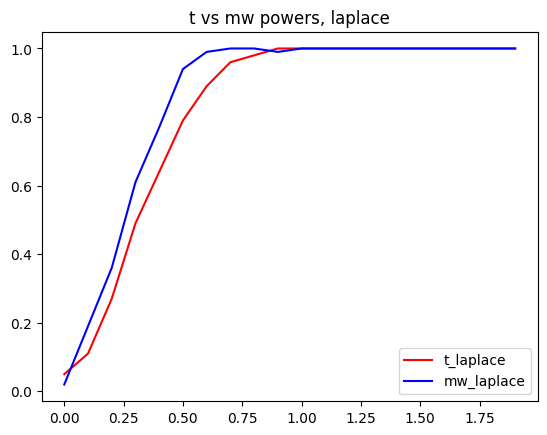

In [5]:
N = 100 #сколько пи вэлью

def a(x):
    return x
        

pval_t_norm = [0]*N
pval_mw_norm = [0]*N
pval_t_laplace = [0]*N
pval_mw_laplace = [0]*N

power_t_norm = [0]*20
power_mw_norm = [0]*20
power_t_laplace = [0]*20
power_mw_laplace = [0]*20

for n in [10, 50, 100]:
    print("n = ", n)
    power_t_norm = [0]*20
    power_mw_norm = [0]*20
    power_t_laplace = [0]*20
    power_mw_laplace = [0]*20
    """
    for k in range(N):
        mu = 1
        x = np.random.normal(0, 1, n)
        y = np.random.normal(mu, 1, n)
        pval_t_norm[k] = sc.stats.ttest_ind(x, y, equal_var=True, alternative='less').pvalue 
        pval_mw_norm[k] = sc.stats.mannwhitneyu(x, y, alternative='less', method = "exact").pvalue
        
        x = np.random.laplace(loc = 0, size = n)
        y = np.random.laplace(loc = mu, size = n)
        pval_t_laplace[k] = sc.stats.ttest_ind(x, y, equal_var=True, alternative='less').pvalue 
        pval_mw_laplace[k] = sc.stats.mannwhitneyu(x, y, alternative='less', method = "exact").pvalue

    b = ft.partial(a,pval_t_norm)
    get_pvalue_info_H1 (b, clr = "red", label = "t_norm",level_array = [0.05, 0.01], mode_output = 1)
    b = ft.partial(a,pval_mw_norm)
    get_pvalue_info_H1 (b, clr = "blue", label = "mw_norm",level_array = [0.05, 0.01], mode_output = 1)
    plt.legend()
    plt.title("t vs mw, normal")
    plt.show()

    b = ft.partial(a,pval_t_laplace)
    get_pvalue_info_H1 (b, clr = "red", label = "t_laplace",level_array = [0.05, 0.01], mode_output = 1)
    b = ft.partial(a,pval_mw_laplace)
    get_pvalue_info_H1 (b, clr = "blue", label = "mw_laplace",level_array = [0.05, 0.01], mode_output = 1)
    plt.legend()
    plt.title("t vs mw, laplace")
    plt.show()
    """
    for j in range(20):
        mu = j/10
        for k in range(N):
            x = np.random.normal(0, 1, n)
            y = np.random.normal(mu, 1, n)
            if(sc.stats.ttest_ind(x, y, equal_var=True, alternative='less').pvalue <=0.05):
                power_t_norm[j]+=1/N
            if(sc.stats.mannwhitneyu(x, y, alternative='less', method = "exact").pvalue <=0.05):
                power_mw_norm[j]+=1/N 

            x = np.random.laplace(loc = 0, size = n)
            y = np.random.laplace(loc = mu, size = n)
            if(sc.stats.ttest_ind(x, y, equal_var=True, alternative='less').pvalue <=0.05):
                power_t_laplace[j]+=1/N
            if(sc.stats.mannwhitneyu(x, y, alternative='less', method = "exact").pvalue <=0.05):
                power_mw_laplace[j]+=1/N   
    plt.plot([j/10 for j in range(20)], power_t_norm, label = "t_norm", color = "red")
    plt.plot([j/10 for j in range(20)], power_mw_norm, label = "mw_norm", color = "blue")
    plt.title("t vs mw powers, normal")
    plt.legend()
    plt.show()

    plt.plot([j/10 for j in range(20)], power_t_laplace, label = "t_laplace", color = "red")
    plt.plot([j/10 for j in range(20)], power_mw_laplace, label = "mw_laplace", color = "blue")
    plt.title("t vs mw powers, laplace")
    plt.legend()
    plt.show()

In [ ]:
ev не роляет

n =  10


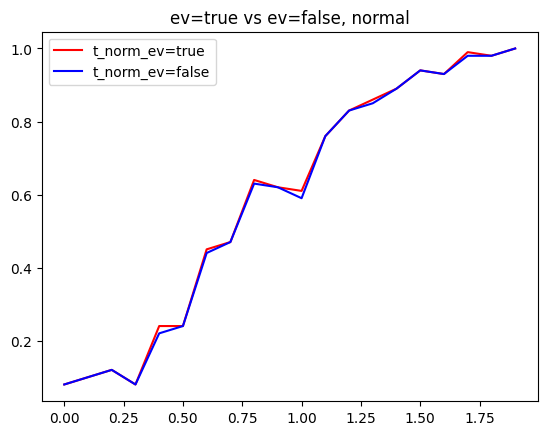

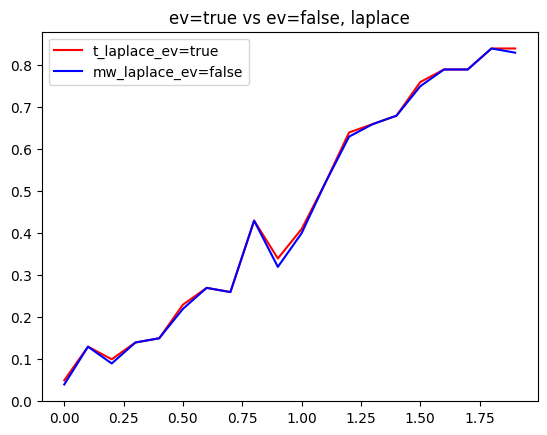

n =  50


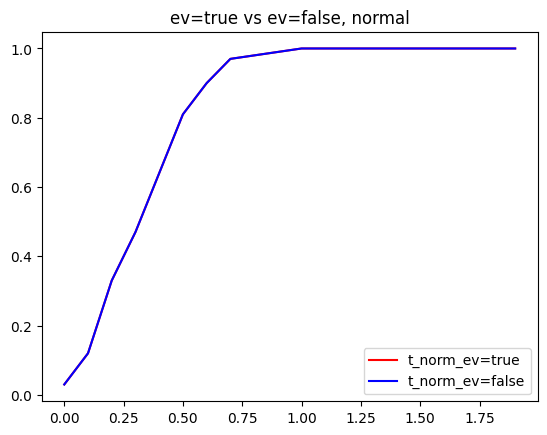

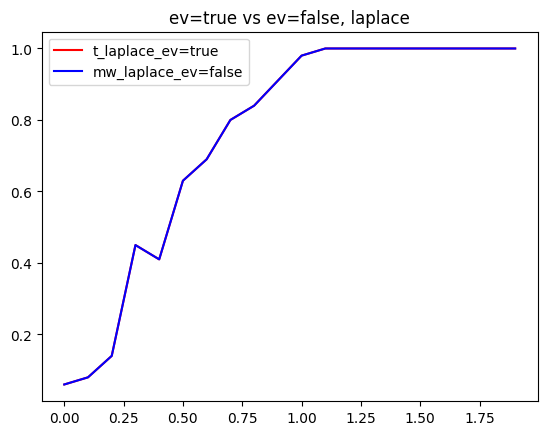

n =  100


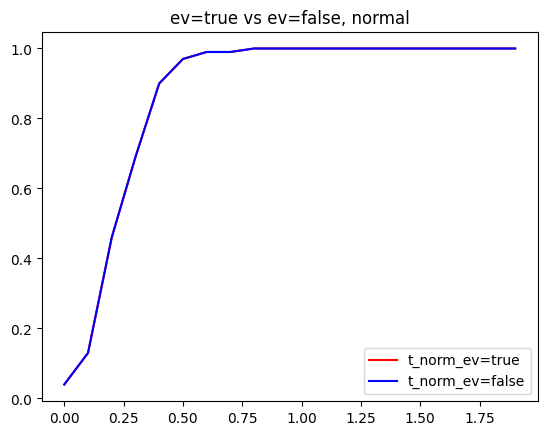

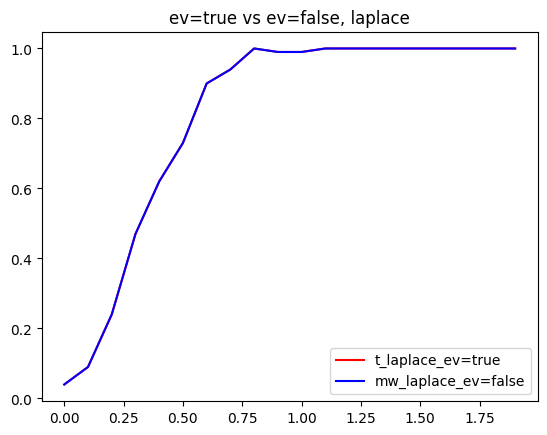

In [4]:
N = 100 #сколько пи вэлью

def a(x):
    return x
        

pval_t_norm = [0]*N
pval_mw_norm = [0]*N
pval_t_laplace = [0]*N
pval_mw_laplace = [0]*N

power_t_norm = [0]*20
power_mw_norm = [0]*20
power_t_laplace = [0]*20
power_mw_laplace = [0]*20

for n in [10, 50, 100]:
    print("n = ", n)
    power_t_norm = [0]*20
    power_mw_norm = [0]*20
    power_t_laplace = [0]*20
    power_mw_laplace = [0]*20
    for j in range(20):
        mu = j/10
        for k in range(N):
            x = np.random.normal(0, 1, n)
            y = np.random.normal(mu, 1, n)
            if(sc.stats.ttest_ind(x, y, equal_var=True, alternative='less').pvalue <=0.05):
                power_t_norm[j]+=1/N
            if(sc.stats.ttest_ind(x, y, equal_var=False, alternative='less').pvalue <=0.05):
                power_mw_norm[j]+=1/N 

            x = np.random.laplace(loc = 0, size = n)
            y = np.random.laplace(loc = mu, size = n)
            if(sc.stats.ttest_ind(x, y, equal_var=True, alternative='less').pvalue <=0.05):
                power_t_laplace[j]+=1/N
            if(sc.stats.ttest_ind(x, y, equal_var=False, alternative='less').pvalue <=0.05):
                power_mw_laplace[j]+=1/N  
    plt.plot([j/10 for j in range(20)], power_t_norm, label = "t_norm_ev=true", color = "red")
    plt.plot([j/10 for j in range(20)], power_mw_norm, label = "t_norm_ev=false", color = "blue")
    plt.title("ev=true vs ev=false, normal")
    plt.legend()
    plt.show()

    plt.plot([j/10 for j in range(20)], power_t_laplace, label = "t_laplace_ev=true", color = "red")
    plt.plot([j/10 for j in range(20)], power_mw_laplace, label = "mw_laplace_ev=false", color = "blue")
    plt.title("ev=true vs ev=false, laplace")
    plt.legend()
    plt.show()

In [ ]:
exact/asymptotic не роляет

n =  10


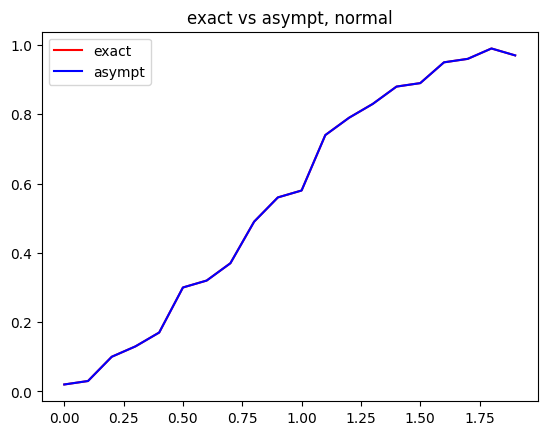

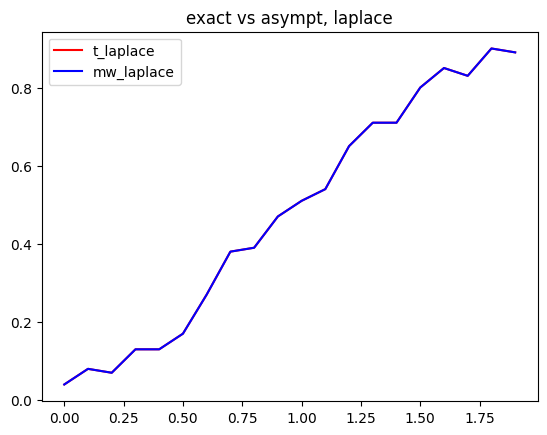

n =  50


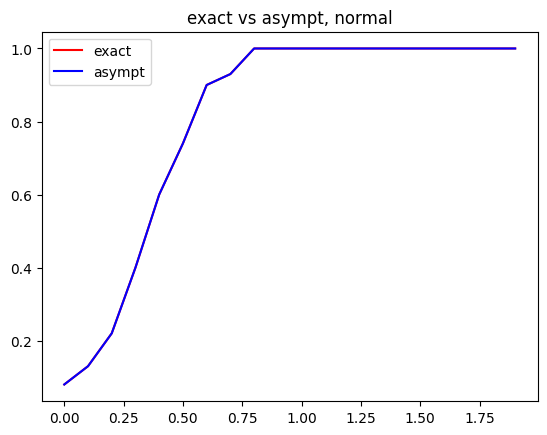

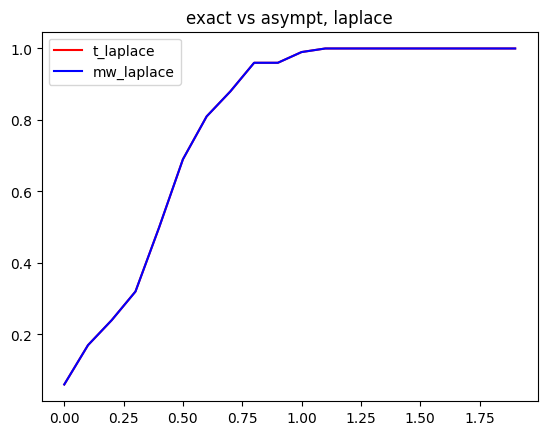

n =  100


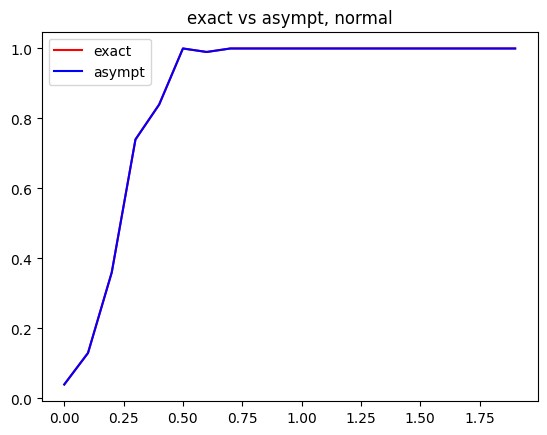

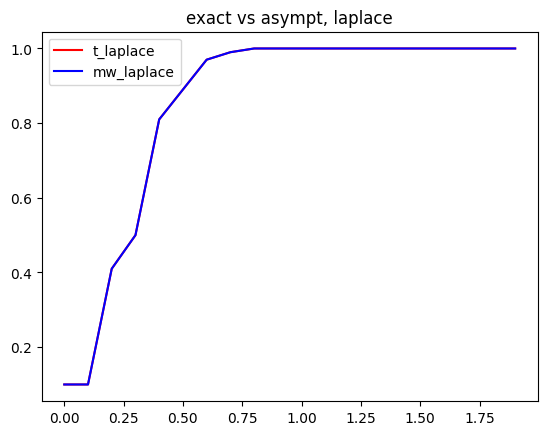

In [7]:
N = 100 #сколько пи вэлью

def a(x):
    return x
        

pval_t_norm = [0]*N
pval_mw_norm = [0]*N
pval_t_laplace = [0]*N
pval_mw_laplace = [0]*N

power_t_norm = [0]*20
power_mw_norm = [0]*20
power_t_laplace = [0]*20
power_mw_laplace = [0]*20

for n in [10, 50, 100]:
    print("n = ", n)
    power_t_norm = [0]*20
    power_mw_norm = [0]*20
    power_t_laplace = [0]*20
    power_mw_laplace = [0]*20
    for j in range(20):
        mu = j/10
        for k in range(N):
            x = np.random.normal(0, 1, n)
            y = np.random.normal(mu, 1, n)
            if(sc.stats.mannwhitneyu(x, y, alternative='less', method = "exact").pvalue <=0.05):
                power_t_norm[j]+=1/N
            if(sc.stats.mannwhitneyu(x, y, alternative='less', method = "asymptotic").pvalue <=0.05):
                power_mw_norm[j]+=1/N 

            x = np.random.laplace(loc = 0, size = n)
            y = np.random.laplace(loc = mu, size = n)
            if(sc.stats.mannwhitneyu(x, y, alternative='less', method = "exact").pvalue <=0.05):
                power_t_laplace[j]+=1/N
            if(sc.stats.mannwhitneyu(x, y, alternative='less', method = "asymptotic").pvalue <=0.05):
                power_mw_laplace[j]+=1/N   
    plt.plot([j/10 for j in range(20)], power_t_norm, label = "exact", color = "red")
    plt.plot([j/10 for j in range(20)], power_mw_norm, label = "asympt", color = "blue")
    plt.title("exact vs asympt, normal")
    plt.legend()
    plt.show()

    plt.plot([j/10 for j in range(20)], power_t_laplace, label = "t_laplace", color = "red")
    plt.plot([j/10 for j in range(20)], power_mw_laplace, label = "mw_laplace", color = "blue")
    plt.title("exact vs asympt, laplace")
    plt.legend()
    plt.show()

In [ ]:
B-W-S

C:\Users\MI\AppData\Local\Temp\ipykernel_3472\3983324090.py:36: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue
C:\Users\MI\AppData\Local\Temp\ipykernel_3472\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


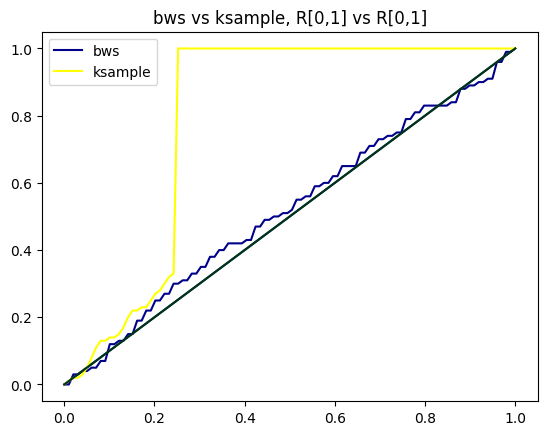

C:\Users\MI\AppData\Local\Temp\ipykernel_3472\3983324090.py:50: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue
C:\Users\MI\AppData\Local\Temp\ipykernel_3472\3983324090.py:50: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue


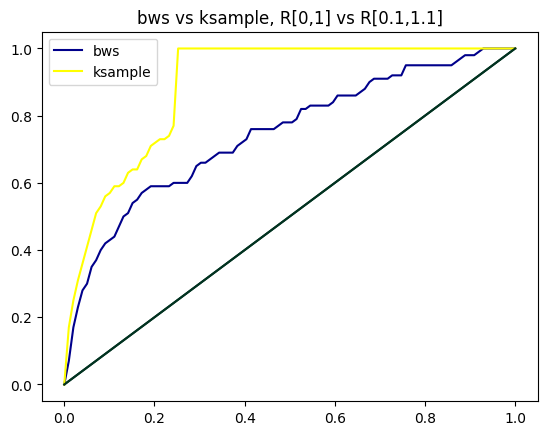

In [13]:
def a(x):
    return x

def bws_stat(x,y):
    n1 = len(x)
    n2 = len(y)
    r = [0]*n1
    s = [0]*n2
    
    z = np.concatenate((x,y)) 
    w = sc.stats.rankdata(z)
    r = np.sort(w[n1:])
    s = np.sort(w[:n1])
    sum1 = np.sum ([ (r[i] - (n1+n2)*(i+1)/n1)**2 / (  (i+1)/(n1+1) * (1 - (i+1)/(n1+1)) * (n2*(n2+n1)/n1) )  for i in range(n1)])
    sum2 = np.sum ([ (s[i] - (n1+n2)*(i+1)/n2)**2 / (  (i+1)/(n2+1) * (1 - (i+1)/(n2+1)) * (n1*(n2+n1)/n2) )  for i in range(n2)])
    return ( sum1/(2*n1) + sum2/(2*n2) )

N = 100 # сколько pvalue
n = 40 # размер выборки
bws_loaded = np.loadtxt('ad_values.txt')
pval_bws = [0]*N
pval_ksample = [0]*N

for k in range(N):
    x = np.random.uniform(0,1, size = n)
    y = np.random.uniform(0,1, size = n)
    pval_bws[k] = sc.stats.permutation_test(data = [x, y], statistic = bws_stat,  n_resamples=100, alternative='two-sided').pvalue
    pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
plt.title("bws vs ksample, R[0,1] vs R[0,1]")
plt.legend()
plt.show()

for k in range(N):
    x = np.random.uniform(0,1, size = n)
    y = np.random.uniform(0.1,1.1, size = n)
    pval_bws[k] = sc.stats.permutation_test(data = [x, y], statistic = bws_stat,  n_resamples=1000, alternative='two-sided').pvalue
    pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
plt.title("bws vs ksample, R[0,1] vs R[0.1,1.1]")
plt.legend()
plt.show()

C:\Users\MI\AppData\Local\Temp\ipykernel_14640\2538542818.py:35: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue
C:\Users\MI\AppData\Local\Temp\ipykernel_14640\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


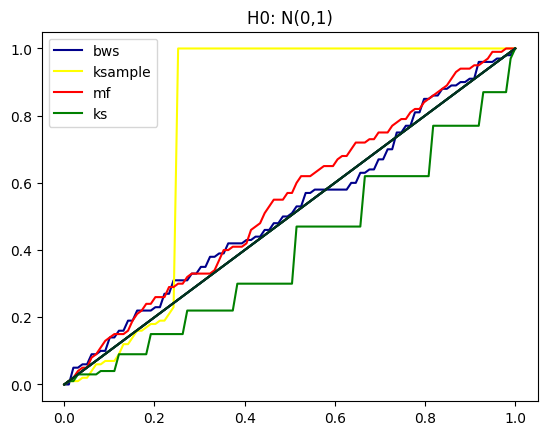

C:\Users\MI\AppData\Local\Temp\ipykernel_14640\2538542818.py:35: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue


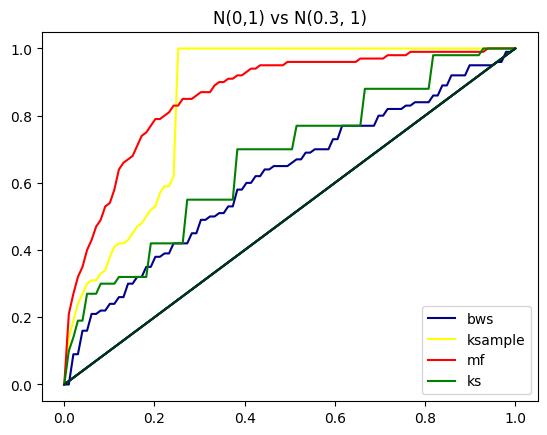

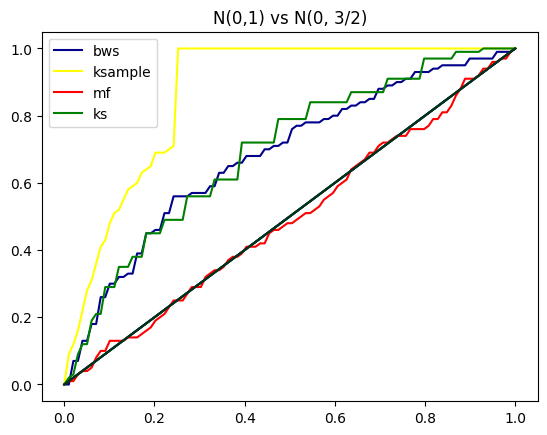

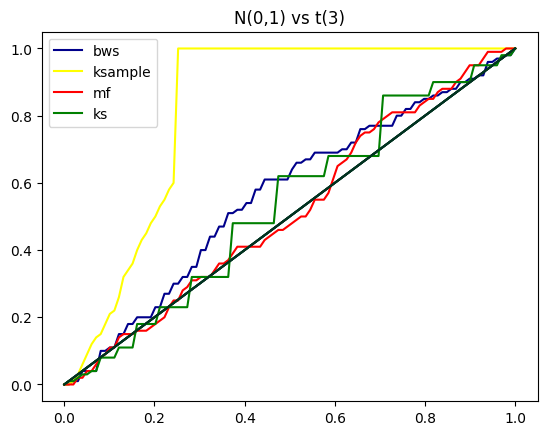

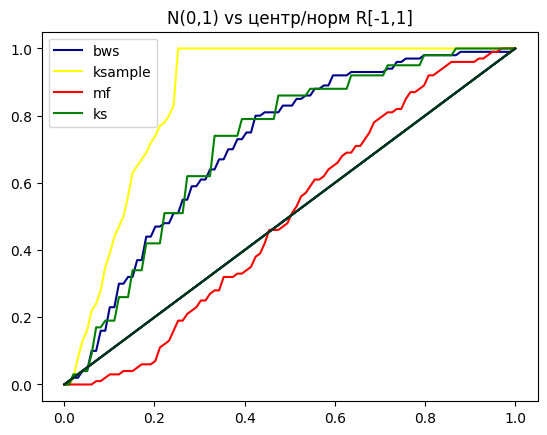

In [18]:
def a(x):
    return x

def bws_stat(x,y):
    n1 = len(x)
    n2 = len(y)
    r = [0]*n1
    s = [0]*n2
    
    z = np.concatenate((x,y)) 
    w = sc.stats.rankdata(z)
    r = np.sort(w[n1:])
    s = np.sort(w[:n1])
    sum1 = np.sum ([ (r[i] - (n1+n2)*(i+1)/n1)**2 / (  (i+1)/(n1+1) * (1 - (i+1)/(n1+1)) * (n2*(n2+n1)/n1) )  for i in range(n1)])
    sum2 = np.sum ([ (s[i] - (n1+n2)*(i+1)/n2)**2 / (  (i+1)/(n2+1) * (1 - (i+1)/(n2+1)) * (n1*(n2+n1)/n2) )  for i in range(n2)])
    return ( sum1/(2*n1) + sum2/(2*n2) )

def mw_stat(x, y):
    n1, n2 = len(x), len(y)
    stat = 0
    for i in range(n1):
        for j in range(n2):
            if (x[i] > y[j]):
                stat += 1
    return np.sqrt( 12/ ((n1*n2) * (n1+n2)) ) * (stat - n1*n2/2)

def pval_generator(mw_stat, bws_stat, n, N, gen):
    pval_bws = [0]*N
    pval_ksample = [0]*N
    pval_mw = [0]*N
    pval_ks = [0]*N
    for k in range(N):
        x, y = gen(n)
        pval_bws[k] = sc.stats.permutation_test(data = [x, y], statistic = bws_stat,  n_resamples=100, alternative='two-sided').pvalue
        pval_ksample[k] =  sc.stats.anderson_ksamp([x, y], variant = "midrank").pvalue
        pval_mw[k] = 1 - sc.stats.norm.cdf(mw_stat(y,x), 0, 1) # тут важно чтоб выборки в правильном порядке были
        pval_ks[k] = sc.stats.ks_2samp(x, y, alternative='two-sided').pvalue
    return pval_bws, pval_ksample, pval_mw, pval_ks

def gen_a(n):
    return np.random.normal(0 , 1, size = n), np.random.normal(0 , 1, size = n)

def gen_b(n):
    return np.random.normal(0 , 1, size = n), np.random.normal(0.3, 1, size = n)

def gen_c(n):
    return np.random.normal(0 , 1, size = n), np.random.normal(0 , np.sqrt(3/2), size = n)

def gen_d(n):
    return np.random.normal(0 , 1, size = n), sc.stats.t.rvs(df = 3, size = n)

def gen_e(n):
    y = np.random.uniform(-1 , 1, size = n)
    return np.random.normal(0 , 1, size = n), (y - np.mean(y) )/np.std(y) 

N = 100 # сколько pvalue
n = 60 # размер выборки
#bws_loaded = np.loadtxt('ad_values.txt')

pval_bws, pval_ksample, pval_mw, pval_ks = pval_generator(mw_stat, bws_stat, n, N, gen_a)

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_mw)    
get_pvalue_info_H1 (b, clr = "red", label = "mf", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ks)    
get_pvalue_info_H1 (b, clr = "green", label = "ks", level_array = [0.05, 0.01], mode_output = 1)
plt.title("H0: N(0,1)")
plt.legend()
plt.show()

pval_bws, pval_ksample, pval_mw, pval_ks = pval_generator(mw_stat, bws_stat, n, N, gen_b)

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_mw)    
get_pvalue_info_H1 (b, clr = "red", label = "mf", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ks)    
get_pvalue_info_H1 (b, clr = "green", label = "ks", level_array = [0.05, 0.01], mode_output = 1)
plt.title("N(0,1) vs N(0.3, 1)")
plt.legend()
plt.show()


n = 200
pval_bws, pval_ksample, pval_mw, pval_ks = pval_generator(mw_stat, bws_stat, n, N, gen_c)

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_mw)    
get_pvalue_info_H1 (b, clr = "red", label = "mf", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ks)    
get_pvalue_info_H1 (b, clr = "green", label = "ks", level_array = [0.05, 0.01], mode_output = 1)
plt.title("N(0,1) vs N(0, 3/2)")
plt.legend()
plt.show()


n = 100
pval_bws, pval_ksample, pval_mw, pval_ks = pval_generator(mw_stat, bws_stat, n, N, gen_d)

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_mw)    
get_pvalue_info_H1 (b, clr = "red", label = "mf", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ks)    
get_pvalue_info_H1 (b, clr = "green", label = "ks", level_array = [0.05, 0.01], mode_output = 1)
plt.title("N(0,1) vs t(3)")
plt.legend()
plt.show()


n = 200
pval_bws, pval_ksample, pval_mw, pval_ks = pval_generator(mw_stat, bws_stat, n, N, gen_e)

b = ft.partial(a, pval_bws)    
get_pvalue_info_H1 (b, clr = "#00008B", label = "bws", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ksample)    
get_pvalue_info_H1 (b, clr = "yellow", label = "ksample", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_mw)    
get_pvalue_info_H1 (b, clr = "red", label = "mf", level_array = [0.05, 0.01], mode_output = 1)
b = ft.partial(a, pval_ks)    
get_pvalue_info_H1 (b, clr = "green", label = "ks", level_array = [0.05, 0.01], mode_output = 1)
plt.title("N(0,1) vs центр/норм R[-1,1]")
plt.legend()
plt.show()

C:\Users\MI\AppData\Local\Temp\ipykernel_5848\2329264048.py:50: UserWarning: p-value capped: true value larger than 0.25. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_sc[k] = sc.stats.anderson_ksamp(x, variant = "continuous").pvalue
C:\Users\MI\AppData\Local\Temp\ipykernel_5848\2329264048.py:50: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  pval_sc[k] = sc.stats.anderson_ksamp(x, variant = "continuous").pvalue
C:\Users\MI\AppData\Local\Temp\ipykernel_5848\634817638.py:25: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


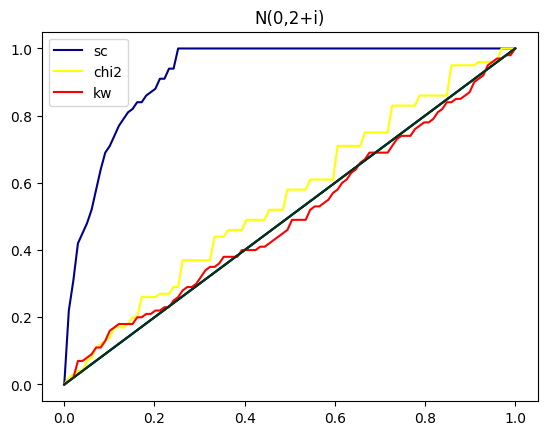

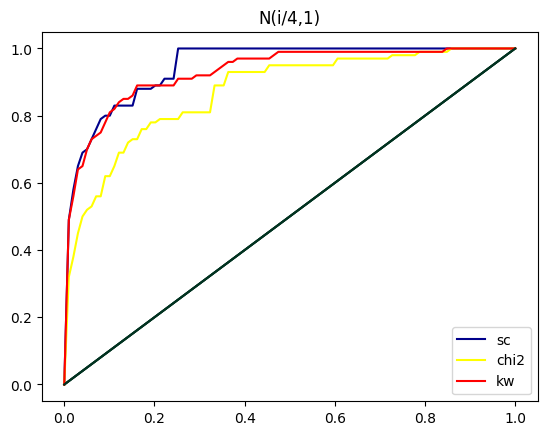

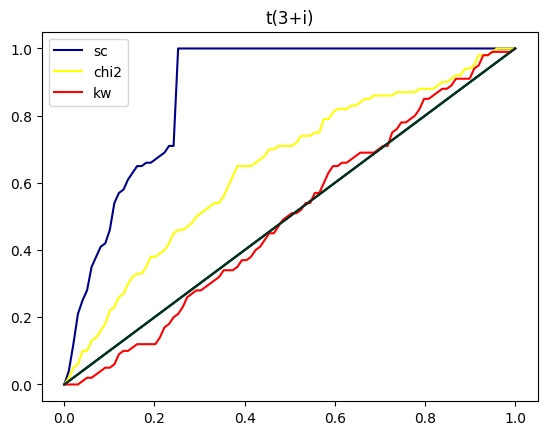

In [6]:
n = 30
N = 100

pval_kw = [0]*N
pval_sc = [0]*N
pval_chi2 = [0]*N

def chi2_pval(samples):
    all_data = np.concatenate(samples)
    n = len(all_data)
    k = int(n ** (1/5))                 
    percen = np.linspace(0, 100, k+1)  
    bins = np.percentile(all_data, percen)
    bins = np.unique(bins)     
    table = []
    for samp in samples:
        cats = np.digitize(samp, bins[:-1]) - 1
        counts = np.bincount(cats, minlength=len(bins)-1)
        table.append(counts)
    return sc.stats.chi2_contingency(table).pvalue

def a(x):
    return x

def gen_a(n):
    x = [0]*4
    for i in range(4):
        x[i] = np.random.normal(0, 2+i, size = n)
    return x

def gen_b(n):
    x = [0]*4
    for i in range(4):
        x[i] = np.random.normal(i/4, 1, size = n)
    return x

def gen_c(n):
    x = [0]*4
    for i in range(4):
        x[i] = sc.stats.t.rvs(df = 3+i, size = n)
    return x

def pval_generator(n, N, gen):
    pval_sc = [0]*N
    pval_chi2 = [0]*N
    pval_kw = [0]*N

    for k in range(N):
        x = gen(n)
        pval_sc[k] = sc.stats.anderson_ksamp(x, variant = "continuous").pvalue
        pval_kw[k] = sc.stats.kruskal(*x, nan_policy='propagate').pvalue
        pval_chi2[k] = chi2_pval(x)
    return pval_sc, pval_chi2, pval_kw

def main_fun(pval_sc, pval_chi2, pval_kw, get_pvalue_info_H1, a):
    b = ft.partial(a, pval_sc)    
    get_pvalue_info_H1 (b, clr = "#00008B", label = "sc", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a, pval_chi2)    
    get_pvalue_info_H1 (b, clr = "yellow", label = "chi2", level_array = [0.05, 0.01], mode_output = 1)
    
    b = ft.partial(a, pval_kw)    
    get_pvalue_info_H1 (b, clr = "red", label = "kw", level_array = [0.05, 0.01], mode_output = 1)

pval_sc, pval_chi2, pval_kw = pval_generator(n, N, gen_a)
main_fun(pval_sc, pval_chi2, pval_kw, get_pvalue_info_H1, a)
plt.title("N(0,2+i)")
plt.legend()
plt.show()


pval_sc, pval_chi2, pval_kw = pval_generator(n, N, gen_b)
main_fun(pval_sc, pval_chi2, pval_kw, get_pvalue_info_H1, a)
plt.title("N(i/4,1)")
plt.legend()
plt.show()

n=1000
pval_sc, pval_chi2, pval_kw = pval_generator(n, N, gen_c)
main_fun(pval_sc, pval_chi2, pval_kw, get_pvalue_info_H1, a)
plt.title("t(3+i)")
plt.legend()
plt.show()